# Household Energy Segmentation, Prediction, and Inequality

Run top to bottom on the cleaned
RECS 2020 file (`recs_cleaned_for_analysis.csv`).

**Pipeline.**
1. Stage I, segmentation: cluster households on annual electricity use (`KWH`) alone; choose K with the
   Silhouette, Calinski–Harabasz, and Davies–Bouldin indices; check robustness across algorithms
   (K-Medoids, Agglomerative, GMM) and stability across seeds (ARI).
2. Statistical separation: one-way ANOVA and Tukey HSD on log-consumption.
3. Inequality: Gini coefficient, nationally and within each segment.
4. Stage II, prediction: six classifiers recover the tier from demographic and structural attributes only;
   confusion matrix and permutation importance follow.
5. Demand regression: OLS with VIF diagnostics and principal-component regression.

**One unified attribute set for all attribute-based analyses.** Both the classifier (Stage II) and the
regression use the same ten predictors: householder age, employment status, income, Census region,
dwelling type, floor area, construction period, wall type, roof type, and insulation adequacy. Segmentation
uses consumption only. This is the leakage-aware separation: the variable that defines the labels is never
a predictor.

**Note.** We have used`RANDOM_SEED = 42`, cluster with `n_init = 10`, and use `log1p` for the ANOVA.

## Requirements

```bash
pip install numpy pandas scikit-learn scipy matplotlib statsmodels xgboost lightgbm kmedoids
```

* `xgboost` and `lightgbm` are needed for classifier; without them the notebook still
  runs and reports the best of the remaining models.
* `statsmodels` provides the Tukey HSD information (a manual VIF fallback is built in).
* `kmedoids` supplies the optional K-Medoids information for robustness; it is skipped cleanly if absent.

Set the dataset path below (or the `RECS_DATA_PATH` environment variable).

In [1]:
IMPLEMENTATION_DETAILS = """
Implementation details and reproducibility

All experiments run in Python 3.13 with scikit-learn, xgboost, lightgbm, statsmodels, kmedoids, numpy, scipy, pandas, and matplotlib, under a single
global seed random_state = 42. Segmentation uses annual consumption (KWH) only; prediction and regression share one set of ten attributes: householder age, employment status, income, and Census region (demographic), plus dwelling type, floor area, construction period, wall type, roof type, and insulation adequacy (structural), with TOTSQFT_EN and HHAGE numeric and the other eight one-hot encoded.

Stage I: KWH z-score standardized, KMeans(n_init=10); K=2..8 scored by Silhouette, Calinski-Harabasz, Davies-Bouldin; K=4 retained, relabelled by ascending mean. Robustness vs K-Medoids (kmedoids.fasterpam on a float32 Euclidean distance matrix), Agglomerative (Ward), and a Gaussian Mixture via ARI; stability = mean/std of pairwise ARI over 20 re-initializations (seeds 0..19).

Validation/inequality: one-way ANOVA (scipy.stats.f_oneway) and Tukey HSD (statsmodels) on log1p(KWH); unweighted Gini nationally and per segment.

Stage II: numeric predictors median-imputed and standardized, categoricals mode-imputed and one-hot encoded (ColumnTransformer); stratified 70/30 split
(test_size=0.3, random_state=42); class-weighted losses where supported.

Models: Logistic Regression (max_iter=1000, multinomial, balanced); SVM (RBF, probability=True, balanced); Decision Tree (balanced); Random Forest
(n_estimators=300, balanced); XGBoost (n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, multi:softprob);
LightGBM (n_estimators=300, num_leaves=31, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, balanced). Scored by accuracy, macro P/R/F1, MCC, macro one-vs-rest ROC-AUC; best model by macro-F1 drives the confusion matrix and permutation importance (n_repeats=10, scoring="f1_macro").

Regression: OLS with VIF diagnostics, plus PCA(n_components=0.95, svd_solver="full") principal-component regression; evaluated by R-squared, MAE, RMSE.
"""
print(IMPLEMENTATION_DETAILS)


Implementation details and reproducibility

All experiments run in Python 3.13 with scikit-learn, xgboost, lightgbm, statsmodels, kmedoids, numpy, scipy, pandas, and matplotlib, under a single
global seed random_state = 42. Segmentation uses annual consumption (KWH) only; prediction and regression share one set of ten attributes: householder age, employment status, income, and Census region (demographic), plus dwelling type, floor area, construction period, wall type, roof type, and insulation adequacy (structural), with TOTSQFT_EN and HHAGE numeric and the other eight one-hot encoded.

Stage I: KWH z-score standardized, KMeans(n_init=10); K=2..8 scored by Silhouette, Calinski-Harabasz, Davies-Bouldin; K=4 retained, relabelled by ascending mean. Robustness vs K-Medoids (kmedoids.fasterpam on a float32 Euclidean distance matrix), Agglomerative (Ward), and a Gaussian Mixture via ARI; stability = mean/std of pairwise ARI over 20 re-initializations (seeds 0..19).

Validation/inequality: o

In [2]:
# If needed, uncomment to install:
# !pip install numpy pandas scikit-learn scipy matplotlib statsmodels xgboost lightgbm kmedoids

In [3]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MultipleLocator
from matplotlib.patches import Patch

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, accuracy_score, precision_score, recall_score,
                             f1_score, balanced_accuracy_score, matthews_corrcoef, roc_auc_score,
                             confusion_matrix, pairwise_distances)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.decomposition import PCA
from scipy import stats

warnings.filterwarnings("ignore")
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Optional dependencies (handled gracefully)
try:
    from xgboost import XGBClassifier; XGB_OK = True
except Exception: XGB_OK = False
try:
    from lightgbm import LGBMClassifier; LGB_OK = True
except Exception: LGB_OK = False
try:
    import kmedoids as _kmedoids_pkg; KMED_OK = True
except Exception: KMED_OK = False
try:
    from statsmodels.stats.multicomp import pairwise_tukeyhsd; SM_OK = True
except Exception: SM_OK = False
print(f"xgboost={XGB_OK}  lightgbm={LGB_OK}  kmedoids={KMED_OK}  statsmodels={SM_OK}")

xgboost=True  lightgbm=True  kmedoids=True  statsmodels=True


In [4]:
# Figure style
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8, "axes.linewidth": 0.8,
    "axes.edgecolor": "#444444", "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight",
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
TIER_COLORS = {"Low": "#9EC9E8", "Moderate": "#5B9BD5", "High": "#2E6DB4", "Very High": "#15375B"}
ACCENT, LINE, GRID = "#E8590C", "#1C6FB8", "#D9D9D9"
TIERS = ["Low", "Moderate", "High", "Very High"]
def despine(ax):
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
def thousands(x, pos): return f"{x:,.0f}"
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)

## 1. Data and feature groups

Segmentation uses annual consumption (`KWH`) only. Prediction and regression share one attribute set of ten
predictors: householder age, employment, income, Census region, dwelling type, floor area, construction
period, wall type, roof type, and insulation adequacy.

In [5]:
DATA_PATH = os.environ.get("RECS_DATA_PATH", "recs_cleaned_for_analysis.csv")
df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH, "| shape:", df.shape)

CLUSTER_FEATURE = "KWH"                       # Stage I input
PREDICTORS = ["HHAGE", "EMPLOYHH", "MONEYPY", "REGIONC",          # demographic (age, employment, income, region)
              "TYPEHUQ", "TOTSQFT_EN", "YEARMADERANGE", "WALLTYPE", "ROOFTYPE", "ADQINSUL"]  # structural
NUMERIC = ["TOTSQFT_EN", "HHAGE"]             # standardized
CATEGORICAL = [c for c in PREDICTORS if c not in NUMERIC]         # mode-imputed, one-hot
missing = [c for c in PREDICTORS if c not in df.columns]
print("Predictors (%d):" % len(PREDICTORS), PREDICTORS)
assert not missing, f"missing columns: {missing}" 

Loaded: recs_cleaned_for_analysis.csv | shape: (18496, 13)
Predictors (10): ['HHAGE', 'EMPLOYHH', 'MONEYPY', 'REGIONC', 'TYPEHUQ', 'TOTSQFT_EN', 'YEARMADERANGE', 'WALLTYPE', 'ROOFTYPE', 'ADQINSUL']


## 2. Stage I: consumption-based segmentation

### 2.1 Choosing K
We standardize `KWH` and score K from 2 to 8 with three internal indices.

In [6]:
X_cluster = df[[CLUSTER_FEATURE]].replace([np.inf, -np.inf], np.nan).dropna()
dfc = df.loc[X_cluster.index].copy()
X_scaled = StandardScaler().fit_transform(X_cluster)

rows = []
for k in range(2, 9):
    lab = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=10).fit_predict(X_scaled)
    rows.append({"K": k, "silhouette": silhouette_score(X_scaled, lab),
                 "calinski_harabasz": calinski_harabasz_score(X_scaled, lab),
                 "davies_bouldin": davies_bouldin_score(X_scaled, lab)})
k_df = pd.DataFrame(rows)
print(k_df.to_string(index=False))

 K  silhouette  calinski_harabasz  davies_bouldin
 2    0.620120       27218.532673        0.582733
 3    0.569458       29692.905037        0.566156
 4    0.553497       32115.860036        0.560543
 5    0.542168       34065.477489        0.563172
 6    0.543082       39072.907706        0.516724
 7    0.533981       44744.327987        0.524547
 8    0.531638       50604.795795        0.517531


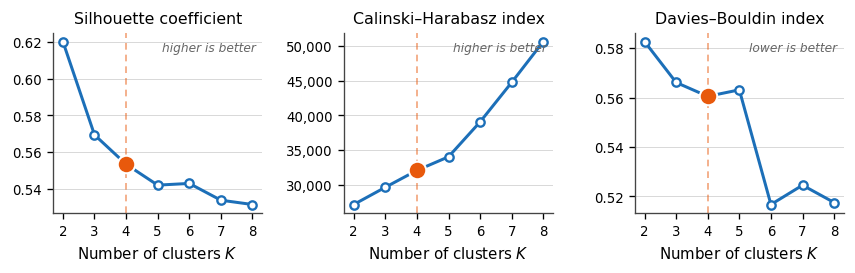

In [7]:
# internal validation metrics vs K
K = k_df["K"].values; i4 = int(np.where(K == 4)[0][0])
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.35))
for ax, col, title, sub in [(axes[0], "silhouette", "Silhouette coefficient", "higher is better"),
                            (axes[1], "calinski_harabasz", "Calinski\u2013Harabasz index", "higher is better"),
                            (axes[2], "davies_bouldin", "Davies\u2013Bouldin index", "lower is better")]:
    y = k_df[col].values
    ax.plot(K, y, "-o", color=LINE, lw=1.8, ms=5, mfc="white", mec=LINE, mew=1.4, zorder=3)
    ax.scatter([4], [y[i4]], s=110, facecolor=ACCENT, edgecolor="white", lw=1.2, zorder=5)
    ax.axvline(4, color=ACCENT, ls=(0, (4, 3)), lw=1.0, alpha=0.55)
    ax.set_title(title, fontsize=9.5, pad=6); ax.set_xlabel("Number of clusters $K$")
    ax.text(0.97, 0.95, sub, transform=ax.transAxes, ha="right", va="top", fontsize=7.3, color="#666", style="italic")
    ax.set_xticks(K); despine(ax); ax.grid(axis="y", color=GRID, lw=0.6, zorder=0)
axes[1].yaxis.set_major_formatter(FuncFormatter(thousands))
fig.tight_layout(w_pad=1.6); fig.savefig(f"{FIG_DIR}/fig_validation.pdf"); plt.show()

### 2.2 Final clustering and profile
We fit K-Means at K = 4 (`n_init = 10`), label tiers by ascending mean usage, and keep the original cluster
ids for traceability. 

In [8]:
K_FINAL = 4
km = KMeans(n_clusters=K_FINAL, random_state=RANDOM_SEED, n_init=10).fit(X_scaled)
dfc["cluster"] = km.labels_
order = dfc.groupby("cluster")["KWH"].mean().sort_values().index.tolist()   # cluster ids, low -> high mean
tier_rank = {cl: i for i, cl in enumerate(order)}          # cluster id -> 0..3 (0 = Low)
dfc["tier_id"] = dfc["cluster"].map(tier_rank)             # integer label used for modeling
dfc["tier"] = dfc["tier_id"].map(dict(enumerate(TIERS)))   # tier name used for display

prof = dfc.groupby("tier_id")["KWH"].agg(n="size", mean="mean", median="median", std="std")
prof["Segment"] = [TIERS[i] for i in prof.index]
prof["ID"] = ["C%d" % order[i] for i in prof.index]        # original cluster id (traceability)
prof = prof[["Segment", "ID", "n", "mean", "median", "std"]].reset_index(drop=True)
print(prof.to_string(index=False))

  Segment ID    n         mean   median          std
      Low C1 7991  5301.344436  5472.94  1894.806574
 Moderate C3 6750 11409.086761 11176.46  1989.386984
     High C0 3149 19395.812956 18778.77  2923.561256
Very High C2  606 33346.463779 30666.60 10626.896708


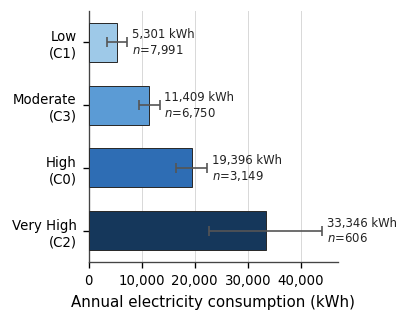

In [9]:
# consumption profile by segment
means, stds = prof["mean"].values, prof["std"].values
ns, ids = prof["n"].values, prof["ID"].values
fig, ax = plt.subplots(figsize=(3.45, 2.75)); ypos = np.arange(4)[::-1]
ax.barh(ypos, means, xerr=stds, color=[TIER_COLORS[t] for t in TIERS], edgecolor="#2b2b2b", lw=0.6,
        height=0.62, error_kw=dict(ecolor="#555", elinewidth=1.0, capsize=3, capthick=1.0), zorder=3)
ax.set_yticks(ypos); ax.set_yticklabels([f"{t}\n({c})" for t, c in zip(TIERS, ids)], fontsize=8)
ax.set_xlabel("Annual electricity consumption (kWh)")
ax.xaxis.set_major_formatter(FuncFormatter(thousands)); ax.set_xlim(0, 47000)
despine(ax); ax.grid(axis="x", color=GRID, lw=0.6, zorder=0)
for yv, m, s, n in zip(ypos, means, stds, ns):
    ax.text(m + s + 900, yv, f"{m:,.0f} kWh\n$n$={n:,}", va="center", ha="left", fontsize=7.0, color="#222")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/fig_profile.pdf"); plt.show()

### 2.3 Robustness across algorithms
Because segmentation uses one variable, close agreement is expected; we report it as a consistency check.
K-Medoids uses the `kmedoids` package when available (it is skipped otherwise).

In [10]:
km_labels = km.labels_
def vrow(name, lab):
    return {"Method": name, "Silhouette": silhouette_score(X_scaled, lab),
            "CH": calinski_harabasz_score(X_scaled, lab), "DB": davies_bouldin_score(X_scaled, lab),
            "ARI_vs_KMeans": adjusted_rand_score(km_labels, lab)}
variants = [vrow("K-Means", km_labels)]
if KMED_OK:
    D = pairwise_distances(X_scaled.astype("float32"), metric="euclidean")
    variants.append(vrow("K-Medoids", _kmedoids_pkg.fasterpam(D, K_FINAL, random_state=RANDOM_SEED).labels))
variants.append(vrow("Agglomerative (Ward)",
                     AgglomerativeClustering(n_clusters=K_FINAL, linkage="ward").fit_predict(X_scaled)))
variants.append(vrow("GMM", GaussianMixture(n_components=K_FINAL, random_state=RANDOM_SEED).fit(X_scaled).predict(X_scaled)))
print(pd.DataFrame(variants).to_string(index=False))

              Method  Silhouette           CH       DB  ARI_vs_KMeans
             K-Means    0.553497 32115.860036 0.560543       1.000000
           K-Medoids    0.523690 26293.184853 0.581686       0.496034
Agglomerative (Ward)    0.540099 31166.348243 0.555328       0.590043
                 GMM    0.558863 31845.674843 0.553632       0.834133


### 2.4 Initialization stability

In [11]:
labs = [KMeans(n_clusters=K_FINAL, random_state=s, n_init=10).fit_predict(X_scaled) for s in range(20)]
aris = [adjusted_rand_score(labs[i], labs[j]) for i in range(len(labs)) for j in range(i + 1, len(labs))]
print(f"Stability ARI at K={K_FINAL}: mean={np.mean(aris):.4f}, std={np.std(aris):.4f}")

Stability ARI at K=4: mean=0.9437, std=0.0401


## 3. Statistical separation
Segments are consumption-defined, so these quantify the size of the separation rather than test it.

In [12]:
dfc["log_KWH"] = np.log1p(dfc["KWH"])
groups = [dfc.loc[dfc["cluster"] == c, "log_KWH"].values for c in order]
F, p = stats.f_oneway(*groups)
grand = dfc["log_KWH"].mean()
ssb = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
sst = ((dfc["log_KWH"] - grand) ** 2).sum()
print(f"One-way ANOVA: F({len(order)-1},{len(dfc)-len(order)}) = {F:,.1f}, p = {p:.3e}")
print(f"Between-group SS = {ssb:,.1f}  ({100*ssb/sst:.1f}% of total variance)")
if SM_OK:
    print("\nTukey HSD (log kWh):\n", pairwise_tukeyhsd(dfc["log_KWH"], dfc["tier"], alpha=0.05).summary())
else:
    print("\n[statsmodels missing] install it to reproduce the Tukey table: pip install statsmodels")

One-way ANOVA: F(3,18492) = 18,681.4, p = 0.000e+00
Between-group SS = 6,163.7  (75.2% of total variance)

Tukey HSD (log kWh):
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
 group1    group2  meandiff p-adj  lower   upper  reject
--------------------------------------------------------
    High       Low  -1.3732   0.0 -1.3911 -1.3552   True
    High  Moderate  -0.5348   0.0 -0.5531 -0.5164   True
    High Very High   0.5248   0.0   0.487  0.5626   True
     Low  Moderate   0.8384   0.0  0.8243  0.8525   True
     Low Very High    1.898   0.0  1.8621  1.9339   True
Moderate Very High   1.0596   0.0  1.0234  1.0957   True
--------------------------------------------------------


## 4. Distributional inequality

In [13]:
def gini(x):
    x = np.asarray(x, dtype=float)
    if x.min() < 0: x = x - x.min()
    x = np.sort(x + 1e-9); n = len(x); idx = np.arange(1, n + 1)
    return (2 * np.sum(idx * x)) / (n * np.sum(x)) - (n + 1) / n

gini_nat = gini(dfc["KWH"].values); total = dfc["KWH"].sum()
gtab = []
for t in TIERS:
    m = dfc["tier"] == t
    gtab.append({"tier": t, "n": int(m.sum()), "household_%": 100*m.mean(),
                 "consumption_%": 100*dfc.loc[m, "KWH"].sum()/total, "Gini": gini(dfc.loc[m, "KWH"].values)})
gtab = pd.DataFrame(gtab)
print(f"National (unweighted) Gini = {gini_nat:.3f}\n")
print(gtab.to_string(index=False))
hi = dfc["tier"].isin(["High", "Very High"])
print(f"\nHigh+Very High: {100*hi.mean():.1f}% of households, {100*dfc.loc[hi,'KWH'].sum()/total:.1f}% of consumption")

National (unweighted) Gini = 0.335

     tier    n  household_%  consumption_%     Gini
      Low 7991    43.203936      21.111879 0.204635
 Moderate 6750    36.494377      38.379065 0.100060
     High 3149    17.025303      30.438299 0.085108
Very High  606     3.276384      10.070758 0.116794

High+Very High: 20.3% of households, 40.5% of consumption


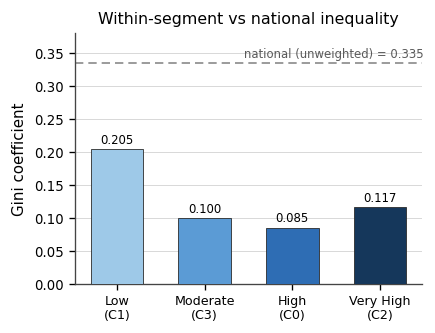

In [14]:
fig, ax = plt.subplots(figsize=(3.7, 2.85)); x = np.arange(4)
ax.bar(x, gtab["Gini"].values, width=0.6, color=[TIER_COLORS[t] for t in TIERS], edgecolor="#2b2b2b", lw=0.5, zorder=3)
ax.axhline(gini_nat, color="#8a8a8a", ls=(0, (5, 3)), lw=1.0)
ax.text(3.5, gini_nat + 0.004, f"national (unweighted) = {gini_nat:.3f}", ha="right", va="bottom", fontsize=7, color="#5a5a5a")
for xi, g in zip(x, gtab["Gini"].values): ax.text(xi, g + 0.004, f"{g:.3f}", ha="center", va="bottom", fontsize=7)
ax.set_xticks(x); ax.set_xticklabels([f"{t}\n({c})" for t, c in zip(TIERS, prof['ID'])], fontsize=7.6)
ax.set_ylabel("Gini coefficient"); ax.set_ylim(0, 0.38); ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.set_title("Within-segment vs national inequality", fontsize=9.5, pad=6)
despine(ax); ax.grid(axis="y", color=GRID, lw=0.6, zorder=0)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/fig_gini.pdf"); plt.show()

## 5. Stage II: predicting segment membership
We predict the tier from the ten attributes only (consumption withheld). Numeric features are median-imputed
and standardized; categoricals are mode-imputed and one-hot encoded. We use a stratified 70/30 split and
class-weighted losses where supported.

In [15]:
def build_preprocessor():
    try: ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError: ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUMERIC),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", ohe)]), CATEGORICAL)],
        remainder="drop", sparse_threshold=0.0)

X_pred, y = dfc[PREDICTORS].copy(), dfc["tier_id"].values   # integer tier labels (0..3)
X_tr, X_te, y_tr, y_te = train_test_split(X_pred, y, test_size=0.3, random_state=RANDOM_SEED, stratify=y)
n_classes = len(np.unique(y_tr))

def make_logreg():
    try: return LogisticRegression(max_iter=1000, multi_class="multinomial", class_weight="balanced")
    except TypeError: return LogisticRegression(max_iter=1000, class_weight="balanced")

models = {
    "Logistic Regression": make_logreg(),
    "SVM": SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=RANDOM_SEED),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_SEED, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_SEED, class_weight="balanced", n_jobs=-1),
}
if XGB_OK:
    models["XGBoost"] = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, objective="multi:softprob", eval_metric="mlogloss", random_state=RANDOM_SEED)
if LGB_OK:
    models["LightGBM"] = LGBMClassifier(n_estimators=300, num_leaves=31, learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, objective="multiclass", class_weight="balanced", random_state=RANDOM_SEED, verbose=-1)

rows, fitted = [], {}
for name, clf in models.items():
    pipe = Pipeline([("prep", build_preprocessor()), ("clf", clf)]).fit(X_tr, y_tr)
    fitted[name] = pipe; yp = pipe.predict(X_te)
    proba = pipe.predict_proba(X_te) if hasattr(pipe, "predict_proba") else None
    roc = np.nan
    if proba is not None:
        try: roc = roc_auc_score(y_te, proba, multi_class="ovr", average="macro")
        except Exception: pass
    rows.append({"Model": name, "Accuracy": accuracy_score(y_te, yp),
                 "Macro-P": precision_score(y_te, yp, average="macro", zero_division=0),
                 "Macro-R": recall_score(y_te, yp, average="macro", zero_division=0),
                 "Macro-F1": f1_score(y_te, yp, average="macro"),
                 "MCC": matthews_corrcoef(y_te, yp), "ROC-AUC": roc})
results = pd.DataFrame(rows).sort_values(["Macro-F1", "Accuracy"], ascending=False).reset_index(drop=True)
print(results.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
best_model = results.iloc[0]["Model"]; print("\nBest model (by macro-F1):", best_model)

              Model  Accuracy  Macro-P  Macro-R  Macro-F1    MCC  ROC-AUC
                SVM    0.4799   0.3980   0.4541    0.4012 0.2479   0.7460
           LightGBM    0.4851   0.3910   0.4264    0.3966 0.2403   0.7215
            XGBoost    0.5516   0.4693   0.3881    0.3959 0.2845   0.7484
      Random Forest    0.5313   0.4300   0.3771    0.3837 0.2546   0.7262
Logistic Regression    0.4592   0.3894   0.4594    0.3810 0.2399   0.7245
      Decision Tree    0.4493   0.3522   0.3581    0.3543 0.1638   0.5755

Best model (by macro-F1): SVM


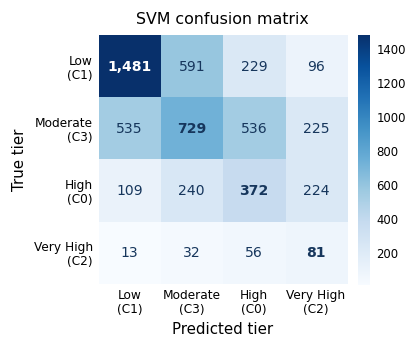

In [16]:
# Confusion matrix for the best model
bp = fitted[best_model]; y_best = bp.predict(X_te)
cm = confusion_matrix(y_te, y_best, labels=list(range(len(TIERS))))
labels = [f"{t}\n({c})" for t, c in zip(TIERS, prof["ID"])]
fig, ax = plt.subplots(figsize=(3.45, 3.05)); im = ax.imshow(cm, cmap="Blues"); vmax = cm.max()
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cm[i,j]:,}", ha="center", va="center", fontsize=8.4,
                color="white" if cm[i, j] > 0.55*vmax else "#16365C", fontweight="bold" if i == j else "normal")
ax.set_xticks(range(4)); ax.set_yticks(range(4)); ax.set_xticklabels(labels, fontsize=7.3); ax.set_yticklabels(labels, fontsize=7.3)
ax.set_xlabel("Predicted tier"); ax.set_ylabel("True tier"); ax.set_title(f"{best_model} confusion matrix", fontsize=9.5, pad=7)
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(length=0); cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); cb.ax.tick_params(labelsize=7, length=0); cb.outline.set_visible(False)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/fig_confusion.pdf"); plt.show()

                       label  importance_mean  importance_std
            Total floor area           0.0436          0.0027
        Census region: South           0.0375          0.0033
             Householder age           0.0071          0.0041
    Census region: Northeast           0.0071          0.0034
Construction period (cat. 5)           0.0034          0.0013
      Dwelling type (cat. 2)           0.0028          0.0027
      Dwelling type (cat. 3)           0.0025          0.0018
  Employment status (cat. 3)           0.0023          0.0020
Insulation adequacy (cat. 3)           0.0022          0.0010
          Roof type (cat. 1)           0.0022          0.0007
         Census region: West           0.0021          0.0017
          Roof type (cat. 2)           0.0020          0.0009

Importance grouped by variable:
group
Census region          0.045738
Total floor area       0.043646
Householder age        0.007137
Dwelling type          0.004526
Construction period    0.00

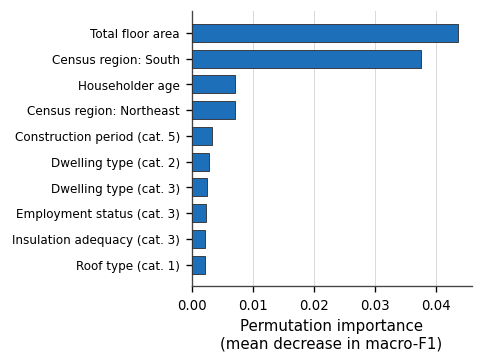

In [17]:
# Permutation importance on the best model, at the encoded-feature level
prep = bp.named_steps["prep"]; clf = bp.named_steps["clf"]
X_te_enc = prep.transform(X_te); feat_names = list(prep.get_feature_names_out())
pi = permutation_importance(clf, X_te_enc, y_te, n_repeats=10, random_state=RANDOM_SEED, n_jobs=-1, scoring="f1_macro")
imp = pd.DataFrame({"feature": feat_names, "importance_mean": pi.importances_mean,
                    "importance_std": pi.importances_std}).sort_values("importance_mean", ascending=False).reset_index(drop=True)

# ---- readable labels ----
NAME = {"TOTSQFT_EN": "Total floor area", "HHAGE": "Householder age",
        "REGIONC": "Census region", "MONEYPY": "Income bracket", "EMPLOYHH": "Employment status",
        "TYPEHUQ": "Dwelling type", "WALLTYPE": "Wall type", "ROOFTYPE": "Roof type",
        "YEARMADERANGE": "Construction period", "ADQINSUL": "Insulation adequacy"}

# OPTIONAL: to print the real RECS meaning instead of "(cat. N)", fill this from the
# official EIA RECS 2020 "Variable and Response Codebook" and the categories will be decoded.
# TYPEHUQ is confirmed from the EIA 2020 questionnaire; fill the rest from the codebook if desired.
RECS_LABELS = {
    # "TYPEHUQ": {"1": "Mobile home", "2": "Single-family detached", "3": "Single-family attached",
    #             "4": "Apartment, 2-4 units", "5": "Apartment, 5+ units"},
    # "ADQINSUL": {"1": "Well insulated", "2": "Adequately insulated", "3": "Poorly insulated", "4": "Not insulated"},
    # "MONEYPY": {...}, "EMPLOYHH": {...}, "YEARMADERANGE": {...}, "WALLTYPE": {...}, "ROOFTYPE": {...},
}

def pretty(feat):
    """Turn an encoder feature name into a reader-friendly label."""
    if feat.startswith("num__"):
        col = feat[5:]; return NAME.get(col, col.replace("_", " "))
    if feat.startswith("cat__"):
        body = feat[5:]
        for col in sorted(NAME, key=len, reverse=True):      # match the base column name
            if body == col or body.startswith(col + "_"):
                cat = body[len(col) + 1:] if body.startswith(col + "_") else ""
                name = NAME[col]
                if not cat:
                    return name
                if col in RECS_LABELS and cat in RECS_LABELS[col]:
                    return f"{name}: {RECS_LABELS[col][cat]}"
                if col == "REGIONC":
                    return f"{name}: {cat.title()}"               # region values are already words
                return f"{name} (cat. {cat})"
        return body.replace("_", " ")
    return feat.replace("num__", "").replace("cat__", "").replace("_", " ")

imp["label"] = imp["feature"].map(pretty)
print(imp.head(12)[["label", "importance_mean", "importance_std"]].to_string(index=False, float_format=lambda v: f"{v:.4f}"))

def base_var(n):
    b = n.replace("num__", "").replace("cat__", "")
    for col in sorted(NAME, key=len, reverse=True):
        if b == col or b.startswith(col + "_"):
            return NAME[col]
    return b
imp["group"] = imp["feature"].map(base_var)
print("\nImportance grouped by variable:")
print(imp.groupby("group")["importance_mean"].sum().sort_values(ascending=False).to_string())

top = imp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(4.1, 3.1)); yv = np.arange(len(top))
ax.barh(yv, top["importance_mean"].values, color=LINE, edgecolor="#2b2b2b", lw=0.5, height=0.7, zorder=3)
ax.set_yticks(yv); ax.set_yticklabels([pretty(f) for f in top["feature"]], fontsize=7.2)
ax.set_xlabel("Permutation importance\n(mean decrease in macro-F1)")
despine(ax); ax.grid(axis="x", color=GRID, lw=0.6, zorder=0)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/fig_importance.pdf"); plt.show()

## 6. Demand regression (OLS with VIF, and PCR)
We use the same ten predictors. VIF is on the numeric predictors; PCR retains 95% of variance.

In [18]:
Xv = dfc[NUMERIC].apply(pd.to_numeric, errors="coerce").dropna()
def vif_manual(frame):
    out = {}
    for col in frame.columns:
        others = [c for c in frame.columns if c != col]
        r2 = LinearRegression().fit(frame[others], frame[col]).score(frame[others], frame[col]) if others else 0.0
        out[col] = 1.0 / (1.0 - r2) if r2 < 1 else np.inf
    return out
print("VIF (numeric predictors):")
for k_, v in vif_manual(Xv).items(): print(f"  {k_}: {v:.3f}")

Xr, yr = dfc[PREDICTORS].copy(), dfc["log_KWH"].values
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.3, random_state=RANDOM_SEED)
pre = build_preprocessor(); Ztr = pre.fit_transform(Xr_tr); Zte = pre.transform(Xr_te)
pca = PCA(n_components=0.95, svd_solver="full", random_state=RANDOM_SEED)
Ptr, Pte = pca.fit_transform(Ztr), pca.transform(Zte)
reg = LinearRegression().fit(Ptr, yr_tr); pred = reg.predict(Pte)
print(f"\nPCR ({pca.n_components_} components, 95% variance): R^2={reg.score(Pte, yr_te):.3f}, "
      f"MAE={np.mean(np.abs(yr_te-pred)):.3f}, RMSE={np.sqrt(np.mean((yr_te-pred)**2)):.3f}")

VIF (numeric predictors):
  TOTSQFT_EN: 1.020
  HHAGE: 1.020

PCR (35 components, 95% variance): R^2=0.321, MAE=0.420, RMSE=0.552


---
### Notes
* Figures are written to `figures/` as vector PDFs and shown inline.
* The K-Medoids CH value depends on the K-Medoids backend.

In [19]:
print('done!')

done!
